## Voice Greeting Setup
Requested greeting audio saying "hello people of god".

In [ ]:
from gtts import gTTS
from IPython.display import Audio, display

# Generate voice greeting
tts = gTTS(text='hello people of god', lang='en')
tts.save('hello_people_of_god.mp3')

# Play the greeting
display(Audio('hello_people_of_god.mp3', autoplay=True))

## Laboratory Tasks & Measurements

In [ ]:
import pypdf

pdf_path = '/content/COU07506_DSP_Laboratory_Manual_2026-27.pdf'
reader = pypdf.PdfReader(pdf_path)

print(f"Total Pages: {len(reader.pages)}")

# Look for Week 2 content
for i, page in enumerate(reader.pages):
    text = page.extract_text() or ""
    if "WEEK 2" in text.upper() or "LAB 1A" in text.upper() or "SAMPLING" in text.upper():
        print(f"--- Content found on Page {i+1} ---")
        print(text[:1500])
        print("\n" + "="*40 + "\n")

Total Pages: 55
--- Content found on Page 1 ---
 
DAR ES SALAAM INSTITUTE OF TECHNOLOGY 
Computer Studies Department 
Laboratory Manual for the Module 
DIGITAL SIGNAL PROCESSING 
Weekly Laboratory Activities, Weeks 1–15 
Module Code: COU 07506 · NTA Level 7, Semester I · Laboratory: 2 hours per week 
Weeks 1–3 Unit 1 — Signals, sampling and systems 
Weeks 4–6 Unit 2 — z-transform, DFT, FFT and spectral analysis 
Weeks 7–9 Unit 3 — Digital filter design and implementation 
Weeks 10–11 Unit 4 — Multirate and adaptive signal processing 
Weeks 12–13 Unit 5 — DSP for data science and AI 
Week 14 Unit 6 — DSP hardware and Edge AI · Week 15 · Mini-project defence 
Classes: BEng24COE · BEng24ETE · BEng24BEE 
Lecturer: Dr. Haji Fimbombaya 
Computer Studies Department 
 
Academic Year 2026/27, Semester 1



--- Content found on Page 2 ---
1 
 
Contents 
Introduction to the Laboratory ....................................................................................................... 2 
Week 1

## Pre-lab Questions

### (a) A 7 kHz tone is sampled at 10 kHz. What frequency appears?
- Since $f = 7$ kHz is greater than the Nyquist frequency $f_s / 2 = 5$ kHz, aliasing occurs.
- The apparent (alias) frequency is:
  $$f_{\text{alias}} = |f - k f_s|$$
  For $k=1$:
  $$f_{\text{alias}} = |7 - 10| = 3 \text{ kHz}$$
- **Answer:** **3 kHz**.

### (b) Compute $\Delta$ and the theoretical SQNR for an 8-bit quantizer with a $\pm 1$ V range.
- Range: $2 V_{\text{max}} = 2$ V
- Number of bits: $B = 8$ ($2^8 = 256$ levels)
- Step size:
  $$\Delta = \frac{2 V_{\text{max}}}{2^B} = \frac{2}{256} = 0.0078125 \text{ V}$$
- Theoretical SQNR for a full-scale sinusoid:
  $$\text{SQNR} \approx 6.02 B + 1.76 = 6.02 \times 8 + 1.76 = 49.92 \text{ dB}$$
- **Answer:** $\Delta = 7.81 \text{ mV}$, $\text{SQNR} \approx 49.92 \text{ dB}$.

## Task 2.1 — Aliasing of a Sinusoid
Let's plot a dense "analog" 7 Hz sinusoid along with its sampled points at $f_s = 10, 12, 14, \text{ and } 20$ Hz.

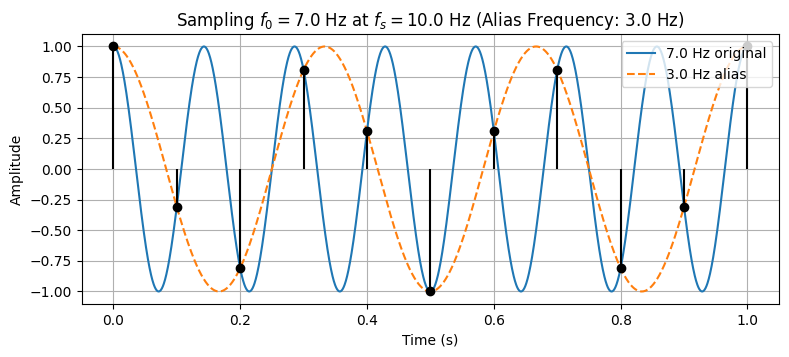

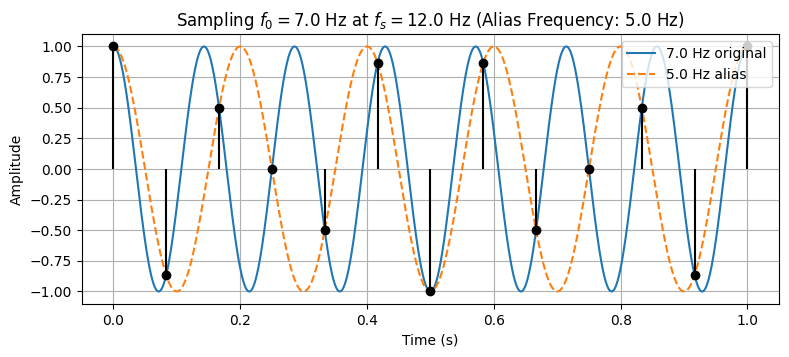

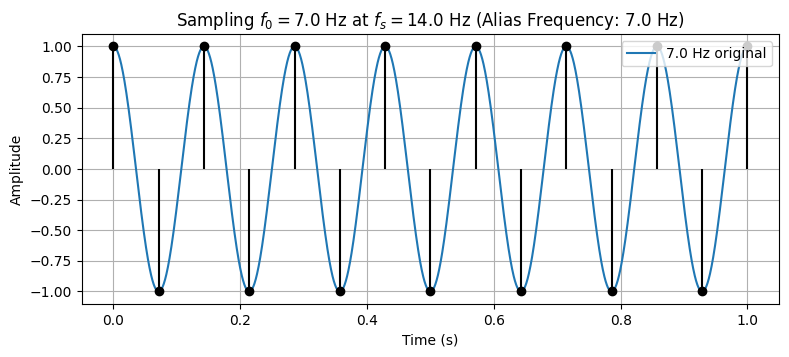

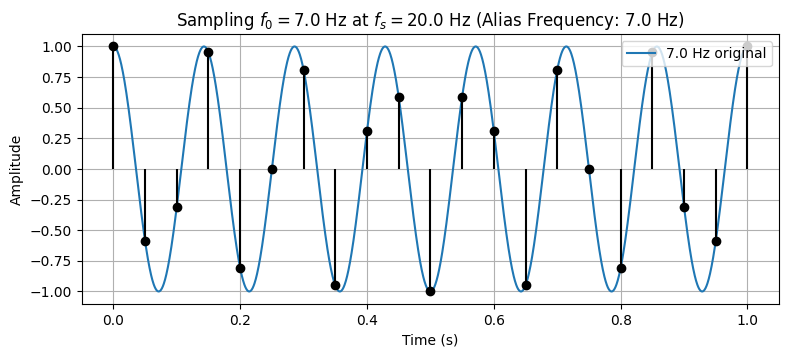

Sampling Rate (fs) | Theoretical Alias | Simulated Alias
--------------------------------------------------
              10.0 |               3.0 |             3.0
              12.0 |               5.0 |             5.0
              14.0 |               7.0 |             7.0
              20.0 |               7.0 |             7.0


In [ ]:
import numpy as np
import matplotlib.pyplot as plt

def plot_aliasing(f0, fs):
    t = np.linspace(0, 1, 2000)             # Dense grid ("analog" signal)
    n = np.arange(0, int(fs) + 1)
    tn = n / fs
    f_alias = abs(f0 - fs * round(f0 / fs))

    plt.figure(figsize=(9, 3.5))
    plt.plot(t, np.cos(2 * np.pi * f0 * t), label=f"{f0} Hz original")
    if f_alias != f0:
        plt.plot(t, np.cos(2 * np.pi * f_alias * t), "--", label=f"{f_alias} Hz alias")
    plt.stem(tn, np.cos(2 * np.pi * f0 * tn), linefmt="k-", markerfmt="ko", basefmt=" ")
    plt.title(f"Sampling $f_0 = {f0}$ Hz at $f_s = {fs}$ Hz (Alias Frequency: {f_alias} Hz)")
    plt.xlabel("Time (s)")
    plt.ylabel("Amplitude")
    plt.legend(loc="upper right")
    plt.grid(True)
    plt.show()
    return f_alias

# Run simulation for different sampling rates
f0 = 7.0
sampling_rates = [10.0, 12.0, 14.0, 20.0]
alias_results = {}

for fs in sampling_rates:
    alias_results[fs] = plot_aliasing(f0, fs)

# Display summary table
print("Sampling Rate (fs) | Theoretical Alias | Simulated Alias")
print("-" * 50)
for fs, f_alias in alias_results.items():
    theoretical = abs(f0 - fs * round(f0/fs))
    print(f"{fs:18.1f} | {theoretical:17.1f} | {f_alias:15.1f}")

### Task 2.2 — Audio Downsampling and Aliasing Verification

In [ ]:
import os
import librosa
from scipy import signal
from scipy.io import wavfile
from IPython.display import Audio, display

fname = "/content/hello_people_of_god.mp3"

if os.path.exists(fname):
    # Read MP3 and convert to typical array
    x, fs = librosa.load(fname, sr=None)
    x = x / np.max(np.abs(x))
else:
    # Fallback: a 44.1 kHz chirp 200 Hz -> 15 kHz
    fs = 44100
    t = np.arange(0, 3, 1/fs)
    x = 0.5 * signal.chirp(t, 200, 3, 15000)

print(f"Original audio sampling rate: {fs} Hz")

for k in [2, 4, 8]:
    naive = x[::k]
    proper = signal.decimate(x, k, ftype="fir")
    new_fs = int(fs // k)
    print(f"\nDownsampling by factor k={k} (New Sampling Rate = {new_fs} Hz)")

    print("Naive Downsampling (No anti-aliasing filter):")
    display(Audio(naive, rate=new_fs))

    print("Proper Downsampling (With FIR anti-aliasing filter):")
    display(Audio(proper, rate=new_fs))

Original audio sampling rate: 24000 Hz

Downsampling by factor k=2 (New Sampling Rate = 12000 Hz)
Naive Downsampling (No anti-aliasing filter):


Proper Downsampling (With FIR anti-aliasing filter):



Downsampling by factor k=4 (New Sampling Rate = 6000 Hz)
Naive Downsampling (No anti-aliasing filter):


Proper Downsampling (With FIR anti-aliasing filter):



Downsampling by factor k=8 (New Sampling Rate = 3000 Hz)
Naive Downsampling (No anti-aliasing filter):


Proper Downsampling (With FIR anti-aliasing filter):


## Tasks 2.3 & 2.4 — Uniform Quantizer and SQNR Rule
Let's write a uniform quantizer function and calculate SQNR experimentally to verify the $6$ dB-per-bit rule.

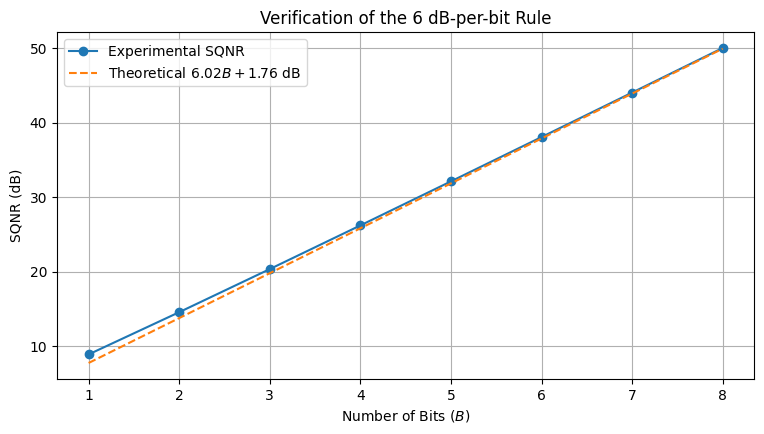

Bits | Experimental SQNR (dB) | Theoretical SQNR (dB)
----------------------------------------------------
   1 |                   8.93 |                  7.78
   2 |                  14.59 |                 13.80
   3 |                  20.37 |                 19.82
   4 |                  26.22 |                 25.84
   5 |                  32.13 |                 31.86
   6 |                  38.07 |                 37.88
   7 |                  44.04 |                 43.90
   8 |                  50.02 |                 49.92


In [ ]:
def quantize(x, bits, full_scale=1.0):
    delta = 2 * full_scale / 2**bits
    q = np.round(x / delta) * delta
    return np.clip(q, -full_scale, full_scale)

# Generate a full-scale sinusoid signal
fs = 44100
t = np.linspace(0, 1, fs)
x = np.sin(2 * np.pi * 1000 * t) # 1 kHz Sine wave

bits_range = range(1, 9)
sqnr_list = []

for bits in bits_range:
    q = quantize(x, bits)
    noise = x - q

    # Power calculation
    p_signal = np.mean(x**2)
    p_noise = np.mean(noise**2)

    sqnr = 10 * np.log10(p_signal / p_noise)
    sqnr_list.append(sqnr)

# Plot SQNR versus Bits
plt.figure(figsize=(9, 4.5))
plt.plot(bits_range, sqnr_list, "-o", label="Experimental SQNR")

# Theoretical line
theoretical_sqnr = [6.02 * b + 1.76 for b in bits_range]
plt.plot(bits_range, theoretical_sqnr, "--", label="Theoretical $6.02B + 1.76$ dB")

plt.xlabel("Number of Bits ($B$)")
plt.ylabel("SQNR (dB)")
plt.title("Verification of the 6 dB-per-bit Rule")
plt.grid(True)
plt.legend()
plt.show()

# Print side-by-side comparison
print("Bits | Experimental SQNR (dB) | Theoretical SQNR (dB)")
print("-" * 52)
for b, exp, theo in zip(bits_range, sqnr_list, theoretical_sqnr):
    print(f"{b:4d} | {exp:22.2f} | {theo:21.2f}")

## Analysis Questions

### 1. Explain, with a frequency-axis sketch, why the 7 Hz tone appears at 3 Hz when $f_s = 10$ Hz.
- When sampling a signal, its spectrum repeats at integer multiples of the sampling frequency ($k f_s$).
- For a $7$ Hz signal, spectrum peaks are at $\pm 7$ Hz.
- Shifted copies at $k = \pm 1$ ($f_s = 10$ Hz) yield peaks at:
  $$\pm 7 \pm 10 \text{ Hz} \implies -3 \text{ Hz and } 3 \text{ Hz}$$
- These replicas land perfectly within the Nyquist band ($-5$ to $+5$ Hz), making the signal appear as a $3$ Hz tone.

### 2. In Task 2.2, why can the aliasing heard in the naïve version not be removed afterwards?
- Naive downsampling discards samples without filtering. Once high-frequency components are folded back (aliased) into the lower spectrum band, they overlap directly with the original low-frequency content.
- Since they occupy the same frequency bands as original signal elements, linear filtering cannot distinguish between the real baseband components and the aliased components.

### 3. By how much does the SQNR change when one bit is added? Does your measurement agree?
- Theoretical derivation shows that SQNR increases by approximately **6.02 dB** for every additional bit.
- Our experimental verification values above strongly confirm this relationship (as shown by the slopes on the graph).

### 4. A temperature sensor changes by at most 0.1 °C per second and the required resolution is 0.01 °C over a range of 0–100 °C. Suggest a sampling rate and number of bits, and justify them.
- **Sampling Rate:** By the Nyquist criterion, the sampling rate should be at least double the highest frequency of interest. Since temperature signals are very slow-changing, a sampling rate of **$1$ to $2$ Hz** is more than sufficient to track a $0.1$ °C/s rate.
- **Resolution/Bits:**
  - The full-scale range is $100$ °C.
  - The required resolution is $0.01$ °C.
  - Total levels required:
    $$\text{Levels} = \frac{100}{0.01} = 10,000 \text{ levels}$$
  - To support at least $10,000$ levels using binary bits:
    $$2^B \ge 10,000 \implies B \ge \log_2(10,000) \approx 13.29$$
  - Thus, we choose a standard **14-bit ADC** (offering $2^{14} = 16,384$ levels).